# PokeGAN — generación condicional de Pokémon (vista frontal y trasera)

GAN condicional entrenada desde cero. A partir de un único vector latente $z$ y del tipo (uno o dos de los 18),
el generador produce la vista **frontal** y la **trasera** de una criatura nueva, en 96×96 px.

| Modelo | Descripción |
|---|---|
| `pura` | Generador y discriminadores entrenados desde cero. |
| `vision` | Mismo generador (desde cero); durante el entrenamiento se añadió un discriminador auxiliar sobre características de ConvNeXt-T congelado. |

**Requisito:** el archivo `pokegan_colab.zip` (código y pesos). Se puede arrastrar al panel *Archivos* de Colab
antes de ejecutar la celda 1, o subirlo cuando la celda lo solicite.

In [1]:
#@title 1. Preparación
import os, sys, zipfile

ZIP = next((p for p in ["pokegan_colab.zip", "../colab/pokegan_colab.zip"] if os.path.exists(p)), None)
if ZIP is None:
    from google.colab import files
    files.upload()
    ZIP = "pokegan_colab.zip"

zipfile.ZipFile(ZIP).extractall("pokegan_colab")
sys.path.insert(0, "pokegan_colab")

from pokegan.demo import cargar_modelos, generar, variar_tipo
cargar_modelos("pokegan_colab/modelos");

modelo 'pura': Entrenado desde cero · paso 27000


modelo 'vision': Desde cero + discriminador auxiliar ConvNeXt-T · paso 28000
dispositivo: cuda


## 2. Generación

Cada columna es una criatura: arriba su vista frontal y abajo la trasera, ambas generadas desde el mismo $z$.
Modificar los valores y ejecutar la celda. La semilla fija las criaturas: la misma semilla reproduce el resultado.

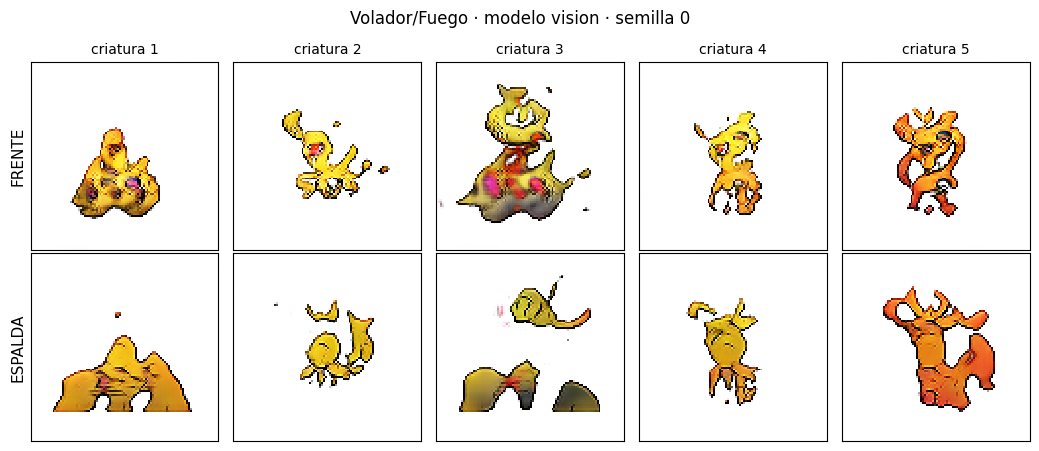

In [2]:
#@title 2. Parámetros
TIPO_1   = "fuego"     #@param ["normal", "lucha", "volador", "veneno", "tierra", "roca", "bicho", "fantasma", "acero", "fuego", "agua", "planta", "electrico", "psiquico", "hielo", "dragon", "siniestro", "hada"]
TIPO_2   = "volador"   #@param ["ninguno", "normal", "lucha", "volador", "veneno", "tierra", "roca", "bicho", "fantasma", "acero", "fuego", "agua", "planta", "electrico", "psiquico", "hielo", "dragon", "siniestro", "hada"]
SEMILLA  = 0           #@param {type:"integer"}
CANTIDAD = 5           #@param {type:"slider", min:1, max:10}
MODELO   = "vision"    #@param ["vision", "pura"]

generar(TIPO_1, TIPO_2, semilla=SEMILLA, cantidad=CANTIDAD, modelo=MODELO);

## 3. Varias combinaciones

Lista de pares `(tipo 1, tipo 2)`; `None` indica un solo tipo. El modelo también acepta combinaciones que no
aparecen en el conjunto de entrenamiento (por ejemplo fuego/hada).

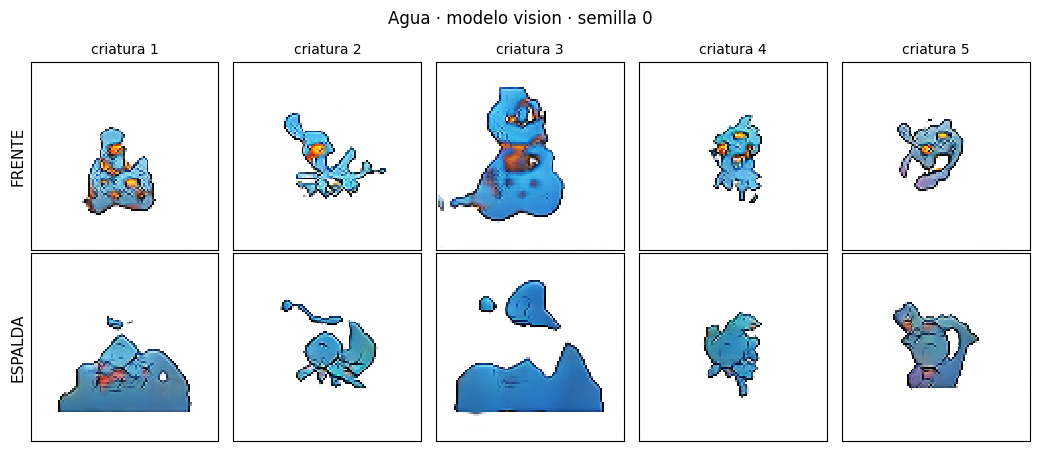

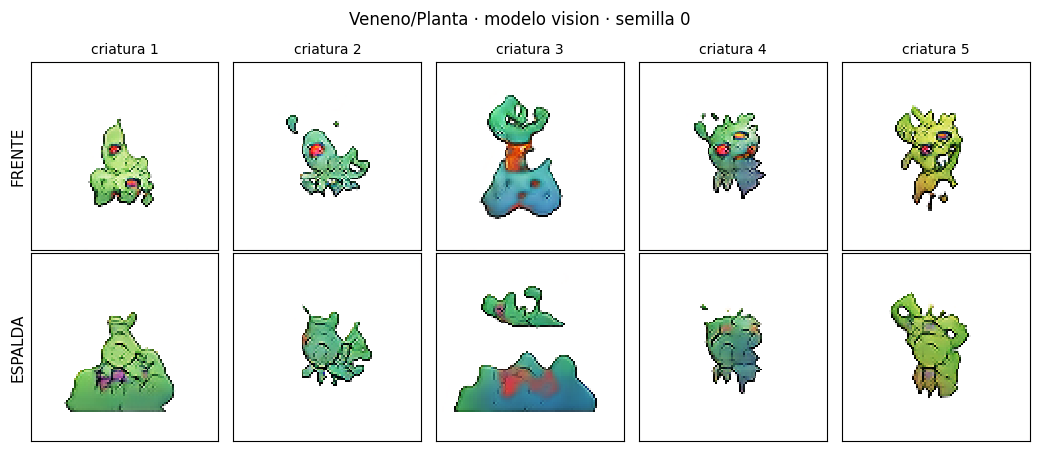

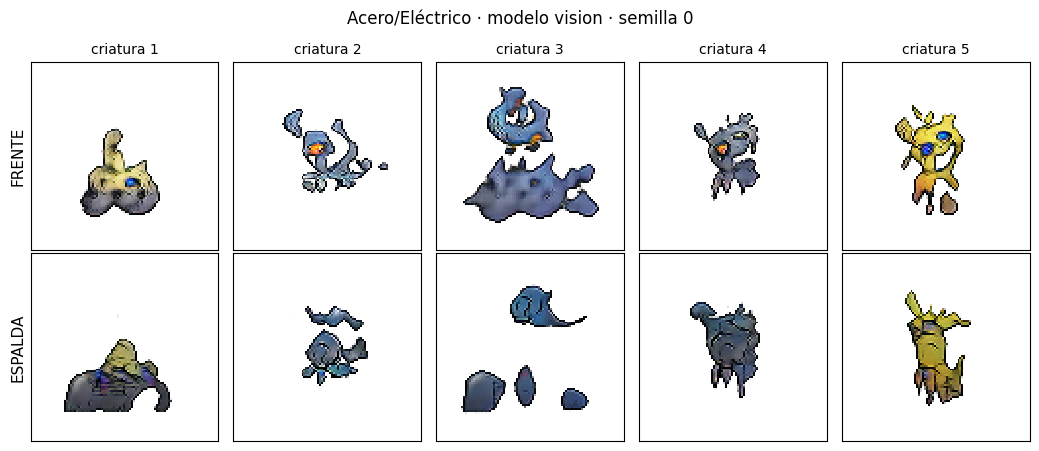

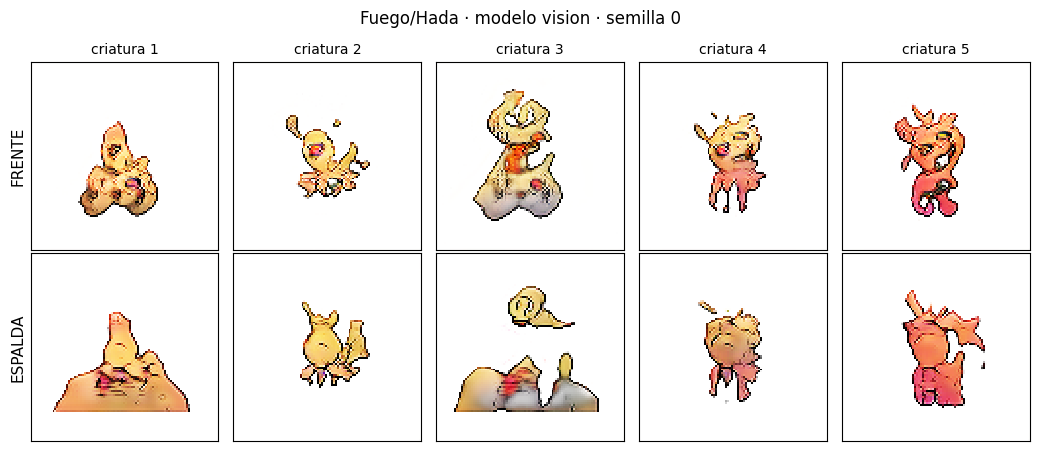

In [3]:
COMBINACIONES = [
    ("agua", None),
    ("planta", "veneno"),
    ("electrico", "acero"),
    ("fuego", "hada"),
]

for tipo_1, tipo_2 in COMBINACIONES:
    generar(tipo_1, tipo_2, semilla=SEMILLA, cantidad=CANTIDAD, modelo=MODELO);

## 4. Efecto del tipo con $z$ fijo

Se mantiene el mismo $z$ y solo se cambia el tipo: $z$ determina la forma y el tipo determina principalmente la paleta.

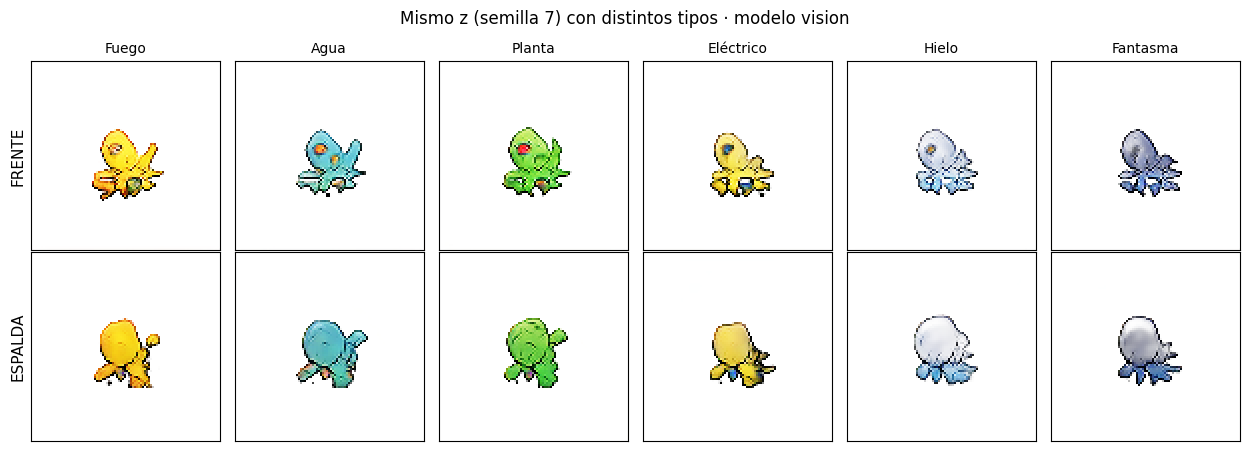

In [4]:
variar_tipo(semilla=7, tipos=["fuego", "agua", "planta", "electrico", "hielo", "fantasma"], modelo=MODELO);

## 5. Opciones adicionales

- `fidelidad=True`: truncamiento de los primeros bloques de $z$ (siluetas más limpias, menor variedad).
- `pixel_art=True`: post-procesamiento con paleta conjunta de 10 colores y limpieza del fondo.

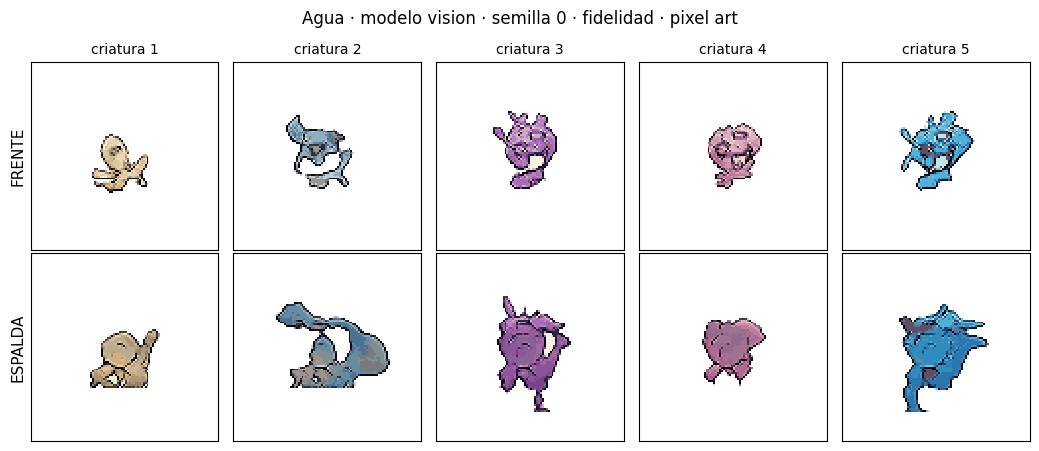

In [5]:
generar("agua", None, semilla=SEMILLA, cantidad=CANTIDAD, modelo=MODELO, fidelidad=True, pixel_art=True);

## 6. Código del modelo

El código fuente completo está en `pokegan_colab/pokegan/` (panel *Archivos*). Las piezas principales:

In [6]:
import inspect
from pokegan.models import generator, discriminator
from pokegan import losses

print(inspect.getsource(generator.Generator.forward))
print(inspect.getsource(discriminator.Discriminator.forward))
print(inspect.getsource(losses.d_hinge))

    def forward(self, z: torch.Tensor, y: torch.Tensor, lam: float = 1.0, return_alpha: bool = False):
        """[B, 6, 96, 96]; con return_alpha=True también devuelve las máscaras α [B, 2, 96, 96] (frente, espalda)."""
        zs = torch.split(z, self.chunk, dim=1)
        e = self.type_embedding(y, lam)
        h = self.stem(zs[0]).view(z.shape[0], -1, 3, 3)
        for i, block in enumerate(self.blocks):
            h = block(h, torch.cat([zs[i + 1], e], 1))
            if self.spatial_z:
                r = h.shape[-1]
                h = h + self.zmap_scale[i].view(1, -1, 1, 1) * self.zmap[i](zs[i + 1]).view(-1, 1, r, r)
            if i == 2 and self.attn is not None:
                h = self.attn(h)
        c = torch.cat([zs[5], e], 1)
        if return_alpha:
            outs = [head(h, c, True) for head in self.heads]
            return torch.cat([o[0] for o in outs], 1), torch.cat([o[1] for o in outs], 1)
        return torch.cat([head(h, c) for head in self.heads], 1)

    